### Practica 3 - RA1
**Alumno** : Gabriel Herrador
**Modulo** : M3 - Programació d'inteligencia artificial

## 1. Entorno, instalación/carga de paquetes y trazabilidad
Verificamos e instalamos (si hace falta) los paquetes necesarios en el proyecto de Julia (`MLJ`, `DataFrames`, `RDatasets`, `StatsBase`, `Random`, `Plots`), medimos el tiempo de inicio, cargamos las librerías y guardamos la versión de Julia junto con el estado de paquetes en `session_info_julia.txt` para asegurar la reproducibilidad.

In [6]:
using Pkg

paquetes = ["MLJ", "DataFrames", "StatsBase", "Random", "Plots"]
deps = Pkg.project().dependencies

for p in paquetes
    if !haskey(deps, p)
        Pkg.add(p)
    end
end

t_inicio = time()

using MLJ
using DataFrames
using StatsBase
using Random
using Plots

println("Julia version: ", VERSION)
open("session_info_julia.txt", "w") do io
    println(io, "Julia version: ", VERSION)
    Pkg.status(io = io)
end

Julia version: 1.13.4


## 2. Carga y exploración inicial del dataset Iris

### Propósito
Cargar el dataset **Iris** en Julia con la misma estructura y variables que en las versiones de Python y R, verificando dimensiones, tipos de datos, ausencia de valores nulos y distribución de las clases antes de dividir y escalar.

### Decisiones y trazabilidad
- **Fuente alternativa en Julia:** Dado que `RDatasets` / `CSV` presenta un error de inicialización (`InitError`) en Julia 1.13, se carga el dataset Iris directamente desde `MLJ` (`@load_iris`) y se consolida en un `DataFrame` con la variable objetivo `species` como texto/categoría uniforme.
- **Inspección previa a la partición:** Se revisan filas, columnas, valores faltantes y frecuencias por especie para confirmar el balanceo original (50 muestras por clase) antes de aplicar la división estratificada 80/20 (`seed = 42`).

### Verificación
- El `DataFrame` tiene **150 filas** y **5 columnas** (4 variables predictoras numéricas + 1 variable objetivo).
- No existen valores faltantes (`missing`) ni `NaN` en las columnas numéricas.
- Cada especie de Iris cuenta con **50 registros** en el conjunto completo.

In [7]:
# Cargar el dataset Iris directamente desde MLJ (evitando conflictos con RDatasets/CSV)
X_iris, y_iris = @load_iris

df_iris = DataFrame(X_iris)
df_iris.species = string.(y_iris)

println("=== Dimensiones del dataset ===")
println("Filas: ", nrow(df_iris), " | Columnas: ", ncol(df_iris))
println("Nombres de columnas: ", names(df_iris))

println("\n=== Primeras 5 filas ===")
display(first(df_iris, 5))

println("\n=== Resumen estadístico descriptivo ===")
display(describe(df_iris, :mean, :std, :min, :median, :max, :nmissing))

println("\n=== Comprobación de NaN en columnas numéricas ===")
num_cols = names(df_iris, Not(:species))
nan_counts = Dict(col => count(isnan, df_iris[!, col]) for col in num_cols)
println(nan_counts)

println("\n=== Distribución de clases (species) ===")
display(countmap(df_iris.species))

=== Dimensiones del dataset ===
Filas: 150 | Columnas: 5
Nombres de columnas: ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

=== Primeras 5 filas ===


Row,sepal_length,sepal_width,petal_length,petal_width,species
,Float64,Float64,Float64,Float64,String
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa



=== Resumen estadístico descriptivo ===


Row,variable,mean,std,min,median,max,nmissing
,Symbol,Union…,Union…,Any,Union…,Any,Int64
1,sepal_length,5.84333,0.828066,4.3,5.8,7.9,0
2,sepal_width,3.054,0.433594,2.0,3.0,4.4,0
3,petal_length,3.75867,1.76442,1.0,4.35,6.9,0
4,petal_width,1.19867,0.763161,0.1,1.3,2.5,0
5,species,,,setosa,,virginica,0



=== Comprobación de NaN en columnas numéricas ===
Dict("petal_length" => 0, "petal_width" => 0, "sepal_length" => 0, "sepal_width" => 0)

=== Distribución de clases (species) ===


Dict{String, Int64} with 3 entries:
  "virginica"  => 50
  "versicolor" => 50
  "setosa"     => 50

## 3. Partición estratificada (80/20) y estandarización en entrenamiento

### Propósito
Dividir el dataset Iris de forma estratificada en un **80 % de entrenamiento** (120 muestras) y un **20 % de prueba** (30 muestras) usando la semilla **`42`**, y estandarizar las variables predictoras (`z-score`) ajustando los parámetros exclusivamente sobre *train* para mantener la coherencia con Python y R y evitar *data leakage*.

### Decisiones y trazabilidad
- **Estratificación y semilla fija (`42`):** Se utiliza `MLJ.partition(..., 0.8, stratify=y_iris, rng=MersenneTwister(42))` para preservar la proporción de las tres clases en ambos conjuntos (40 muestras por especie en *train* y 10 por especie en *test*).
- **Prevención de fuga de datos (*data leakage*):** `StatsBase.fit(ZScoreTransform, X_train_mat, dims=1)` calcula la media y la desviación estándar únicamente sobre `X_train_mat`, aplicando esa misma transformación tanto a *train* como a *test*.

### Verificación
- *Train* tiene **120 filas** y *test* tiene **30 filas**, con reparto equilibrado entre las 3 clases.
- Las variables estandarizadas en `X_train_scaled` presentan media cercana a `0.0` y desviación típica cercana a `1.0` por columna.

In [8]:
# Partición estratificada 80/20 con semilla 42
rng = MersenneTwister(42)
train_idx, test_idx = partition(eachindex(y_iris), 0.8, stratify=y_iris, rng=rng)

X_train_df = df_iris[train_idx, Not(:species)]
X_test_df  = df_iris[test_idx,  Not(:species)]
y_train    = y_iris[train_idx]
y_test     = y_iris[test_idx]

println("=== Tamaños de la partición ===")
println("Train: ", nrow(X_train_df), " filas | Test: ", nrow(X_test_df), " filas")

println("\n=== Distribución de clases en train ===")
display(countmap(string.(y_train)))

println("\n=== Distribución de clases en test ===")
display(countmap(string.(y_test)))

# Estandarización ajustada EXCLUSIVAMENTE en train (evitando data leakage)
X_train_mat = Matrix{Float64}(X_train_df)
X_test_mat  = Matrix{Float64}(X_test_df)

scaler = fit(ZScoreTransform, X_train_mat, dims=1)
X_train_scaled = StatsBase.transform(scaler, X_train_mat)
X_test_scaled  = StatsBase.transform(scaler, X_test_mat)

println("\n=== Verificación de estandarización ===")
println("Media train escalado: ", round.(mean(X_train_scaled, dims=1), digits=4))
println("Std train escalado:   ", round.(std(X_train_scaled, dims=1), digits=4))
println("Media test escalado:  ", round.(mean(X_test_scaled, dims=1), digits=4))

=== Tamaños de la partición ===
Train: 120 filas | Test: 30 filas

=== Distribución de clases en train ===


Dict{String, Int64} with 3 entries:
  "virginica"  => 40
  "versicolor" => 40
  "setosa"     => 40


=== Distribución de clases en test ===


Dict{String, Int64} with 3 entries:
  "virginica"  => 10
  "versicolor" => 10
  "setosa"     => 10


=== Verificación de estandarización ===
Media train escalado: [-0.0 0.0 -0.0 0.0]
Std train escalado:   [1.0 1.0 1.0 1.0]
Media test escalado:  [0.097 -0.0389 0.0459 0.0901]


## 4. Entrenamiento y evaluación del modelo KNN (k = 5)

### Propósito
Entrenar un modelo de clasificación **K-Nearest Neighbors (KNN)** con **`k = 5`** sobre las características estandarizadas del conjunto de entrenamiento y evaluar su capacidad de generalización sobre el conjunto de prueba (30 muestras).

### Decisiones y trazabilidad
- **Hiperparámetro `K = 5`:** Se fija `K = 5` para mantener la consistencia directa con los experimentos realizados en Python y R.
- **Evaluación en test sin fuga:** El modelo se ajusta (`fit!`) únicamente con los datos escalados de entrenamiento (`X_train_scaled`, `y_train`) y se evalúa sobre `X_test_scaled` comparando frente a `y_test` mediante *accuracy* global, matriz de confusión y métricas por clase (precisión, *recall* y F1).

### Verificación
- Se obtienen las 30 predicciones sobre *test* sin errores de tipos ni dimensiones.
- Se muestran el *accuracy* en *test*, la matriz de confusión y el desglose por especie (`setosa`, `versicolor`, `virginica`).

In [12]:
using Statistics

# Cargar el clasificador KNN desde MLJ / NearestNeighborModels
KNNClassifier = @load KNNClassifier pkg=NearestNeighborModels verbosity=0

# MLJ espera tablas para X y CategoricalArray para y
feature_names = Symbol.(names(X_train_df))
X_train_scaled_df = DataFrame(X_train_scaled, feature_names)
X_test_scaled_df  = DataFrame(X_test_scaled,  feature_names)

y_train_cat = categorical(string.(y_train))
y_test_cat  = categorical(string.(y_test))

# Definir y ajustar el modelo con K = 5 exclusivamente sobre train
knn_model = KNNClassifier(K = 5)
mach = machine(knn_model, X_train_scaled_df, y_train_cat)
fit!(mach, verbosity=0)

# Predecir sobre test y extraer etiquetas puntuales
y_pred = predict_mode(mach, X_test_scaled_df)

# Calcular accuracy global en test
n_aciertos = count(y_pred .== y_test_cat)
n_total    = length(y_test_cat)
acc_test   = n_aciertos / n_total

println("=== Evaluación KNN (K = 5) en conjunto de prueba ===")
println("Accuracy en test: ", round(acc_test * 100, digits=2), "% (", n_aciertos, "/", n_total, ")")

# Matriz de confusión de MLJ: confusion_matrix(ŷ, y) -> filas = predicho, columnas = real
cm = confusion_matrix(y_pred, y_test_cat)
println("\n=== Matriz de confusión (MLJ: filas = predicho, columnas = real) ===")
display(cm)

# Tabla de métricas por clase (Precision, Recall, F1)
clases = sort(unique(string.(y_test_cat)))
filas_metricas = []

for c in clases
    pred_c = string.(y_pred) .== c
    real_c = string.(y_test_cat) .== c

    tp = count(pred_c .& real_c)
    fp = count(pred_c .& .!real_c)
    fn = count(.!pred_c .& real_c)

    precision = (tp + fp) > 0 ? tp / (tp + fp) : 0.0
    recall    = (tp + fn) > 0 ? tp / (tp + fn) : 0.0
    f1        = (precision + recall) > 0 ? 2 * precision * recall / (precision + recall) : 0.0

    push!(filas_metricas, (
        Clase     = c,
        Soporte   = tp + fn,
        Precision = round(precision, digits=4),
        Recall    = round(recall, digits=4),
        F1        = round(f1, digits=4)
    ))
end

df_metricas = DataFrame(filas_metricas)
println("\n=== Métricas por clase ===")
display(df_metricas)

=== Evaluación KNN (K = 5) en conjunto de prueba ===
Accuracy en test: 90.0% (27/30)

=== Matriz de confusión (MLJ: filas = predicho, columnas = real) ===


           ┌────────────────────────────────┐
           │          Ground Truth          │
┌──────────┼──────────┬──────────┬──────────┤
│Predicted │  setosa  │versicol… │virginica │
├──────────┼──────────┼──────────┼──────────┤
│  setosa  │    10    │    0     │    0     │
├──────────┼──────────┼──────────┼──────────┤
│versicol… │    0     │    9     │    2     │
├──────────┼──────────┼──────────┼──────────┤
│virginica │    0     │    1     │    8     │
└──────────┴──────────┴──────────┴──────────┘



=== Métricas por clase ===


Row,Clase,Soporte,Precision,Recall,F1
,String,Int64,Float64,Float64,Float64
1,setosa,10,1.0,1.0,1.0
2,versicolor,10,0.8182,0.9,0.8571
3,virginica,10,0.8889,0.8,0.8421


## 5. Visualización de la matriz de confusión (KNN, k = 5)

### Propósito
Generar y guardar una representación visual de la matriz de confusión en el conjunto de prueba para **KNN (`k = 5`)** en Julia, manteniendo el mismo estilo visual y trazabilidad que en las versiones de R y Python.

### Decisiones y trazabilidad
- **Ejes explícitos:** Se representa **Clase Predicha** en el eje vertical y **Clase Real** en el eje horizontal, mostrando el recuento de muestras en cada celda y el *accuracy* en *test* en el título.
- **Exportación del gráfico:** Se guarda la figura como `matriz_confusion_julia.png` en el directorio de trabajo para facilitar su revisión o inclusión en la memoria.

### Verificación
- Se muestra el gráfico con los valores de cada celda y se crea `matriz_confusion_julia.png` sin errores.

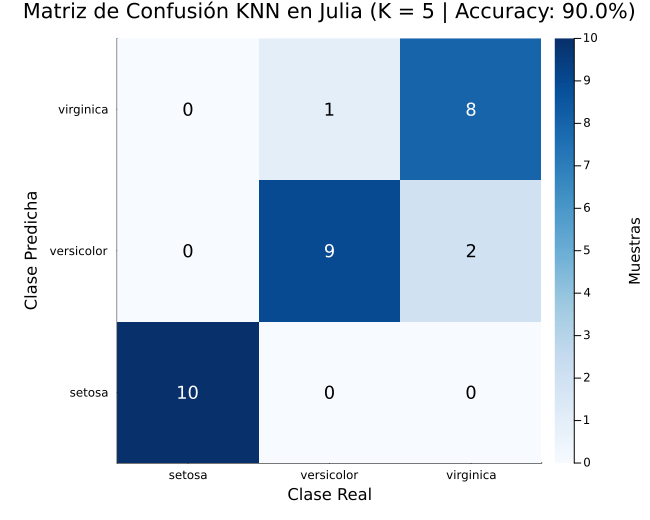

"c:\\Users\\GabrielHerradorÁlvar\\Desktop\\Master BigData e IA\\MP3 - Programació d'inteligencia artificial\\RA1\\Practicas\\Practica 3\\Julia\\matriz_confusion_julia.png"

In [14]:
clases_ord = sort(unique(string.(y_test_cat)))
n_c = length(clases_ord)

# Filas = Clase Predicha, Columnas = Clase Real
mat_counts = zeros(Int, n_c, n_c)
pred_str = string.(y_pred)
real_str = string.(y_test_cat)

for (i, c_pred) in enumerate(clases_ord)
    for (j, c_real) in enumerate(clases_ord)
        mat_counts[i, j] = count((pred_str .== c_pred) .& (real_str .== c_real))
    end
end

acc_pct = round(acc_test * 100, digits=2)

# En Plots.heatmap(x, y, z), z[fila_y, col_x], donde x e y van de 1 a n_c
p_cm = heatmap(
    1:n_c,
    1:n_c,
    mat_counts,
    xlabel = "Clase Real",
    ylabel = "Clase Predicha",
    title  = "Matriz de Confusión KNN en Julia (K = 5 | Accuracy: $(acc_pct)%)",
    color  = :Blues,
    colorbar_title = "\nMuestras",
    aspect_ratio = :equal,
    xlims = (0.5, n_c + 0.5),
    ylims = (0.5, n_c + 0.5),
    xticks = (1:n_c, clases_ord),
    yticks = (1:n_c, clases_ord),
    size = (650, 520),
    grid = false
)

max_val = maximum(mat_counts)
for i in 1:n_c      # eje y -> Clase Predicha
    for j in 1:n_c  # eje x -> Clase Real
        val = mat_counts[i, j]
        txt_color = val > max_val * 0.55 ? :white : :black
        annotate!(p_cm, j, i, text(string(val), 12, txt_color, :center))
    end
end

display(p_cm)
savefig(p_cm, "matriz_confusion_julia.png")